In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/policies_clean.csv")
train_ids = pd.read_csv("../data/processed/train_ids.csv")["IDpol"]
train = df[df["IDpol"].isin(train_ids)].reset_index(drop=True)
assert len(train) == 541_431

OVERALL = train["ClaimNb"].sum() / train["Exposure"].sum()
print("overall frequency:", round(OVERALL, 4))

def freq_table(d, col, bins=None):
    key = d[col] if bins is None else pd.cut(d[col], bins)
    t = d.groupby(key, observed=True).agg(
        policies=("IDpol", "size"),
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
    )
    assert t["policies"].sum() == len(d), f"{col}: rows lost in binning"
    t["exposure_share"] = t["exposure"] / t["exposure"].sum()
    t["freq"] = t["claims"] / t["exposure"]            # sum/sum
    t["relativity"] = t["freq"] / OVERALL              # 1.0 = average risk
    t["thin"] = np.where(t["claims"] < 100, "<100 claims", "")
    return t.round(4)

def plot_freq(t, title):
    fig, ax1 = plt.subplots(figsize=(8, 3.5))
    x = np.arange(len(t))
    ax1.bar(x, t["exposure_share"], color="lightgrey")
    ax1.set_ylabel("exposure share")
    ax1.set_xticks(x)
    ax1.set_xticklabels([str(i) for i in t.index], rotation=45, ha="right")
    ax2 = ax1.twinx()
    ax2.plot(x, t["freq"], "o-", color="tab:red")
    ax2.axhline(OVERALL, ls="--", color="k", lw=0.8)
    ax2.set_ylabel("frequency")
    ax1.set_title(title)
    plt.tight_layout()
    plt.show()

overall frequency: 0.1009


         policies    share
ClaimNb                   
0          514224  0.94975
1           25714  0.04749
2            1424  0.00263
3              57  0.00011
4               6  0.00001
5               1  0.00000
8               1  0.00000
9               1  0.00000
11              2  0.00000
16              1  0.00000 

ClaimNb mean=0.0532  var=0.0575  var/mean=1.08

count    541431.000
mean          0.527
std           0.364
min           0.003
25%           0.170
50%           0.490
75%           0.990
max           1.000
Name: Exposure, dtype: float64 

             policies     exposure  claims  exposure_share    freq  \
Exposure                                                             
(0.0, 0.1]     102065    6020.2916    2755          0.0211  0.4576   
(0.1, 0.25]     76410   13991.1600    2988          0.0490  0.2136   
(0.25, 0.5]    105102   41156.1600    5138          0.1441  0.1248   
(0.5, 0.75]     73952   46834.6300    4753          0.1640  0.1015   
(0.75, 1.0]  

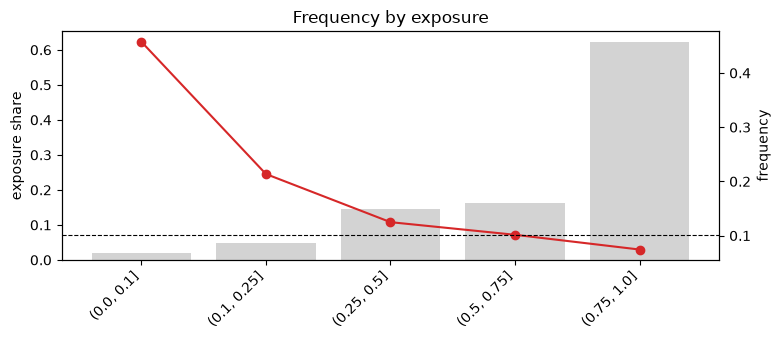

In [2]:
# Claim counts
cnt = train["ClaimNb"].value_counts().sort_index()
print(pd.DataFrame({"policies": cnt, "share": (cnt / len(train)).round(5)}), "\n")

# Overdispersion check: Poisson has variance = mean (per unit of exposure)
m, v = train["ClaimNb"].mean(), train["ClaimNb"].var()
print(f"ClaimNb mean={m:.4f}  var={v:.4f}  var/mean={v/m:.2f}\n")

# Exposure
print(train["Exposure"].describe().round(3), "\n")
t = freq_table(train, "Exposure", [0, 0.1, 0.25, 0.5, 0.75, 1.0])
print(t, "\n")          # freq should be ~flat if claims scale with exposure
plot_freq(t, "Frequency by exposure")

=== DrivAge ===
           policies    exposure  claims  exposure_share    freq  relativity  \
DrivAge                                                                       
(17, 21]       9085   3566.2614     794          0.0125  0.2226      2.2061   
(21, 25]      22173   9490.8740    1465          0.0332  0.1544      1.5295   
(25, 30]      52545  23277.8133    2463          0.0815  0.1058      1.0484   
(30, 40]     135423  66591.4722    5978          0.2332  0.0898      0.8895   
(40, 50]     131864  70148.7649    7339          0.2457  0.1046      1.0366   
(50, 60]     107936  60417.1182    5829          0.2116  0.0965      0.9560   
(60, 70]      50955  30549.5430    2849          0.1070  0.0933      0.9241   
(70, 100]     31450  21492.5747    2100          0.0753  0.0977      0.9681   

          thin  
DrivAge         
(17, 21]        
(21, 25]        
(25, 30]        
(30, 40]        
(40, 50]        
(50, 60]        
(60, 70]        
(70, 100]        



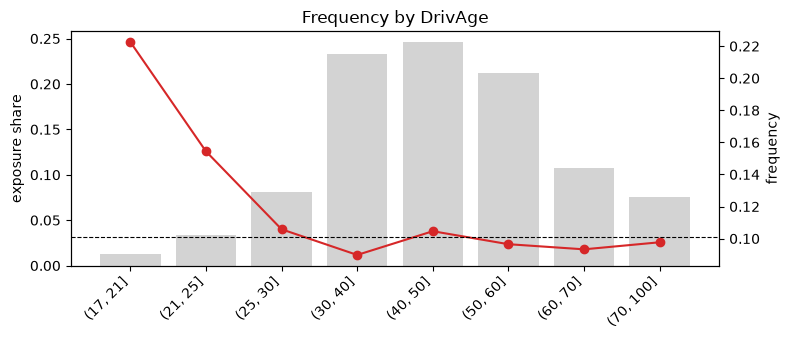

=== VehAge ===
           policies    exposure  claims  exposure_share    freq  relativity  \
VehAge                                                                        
(-1, 0]       45978  13192.3112    4173          0.0462  0.3163      3.1343   
(0, 1]        56941  26061.1174    2327          0.0913  0.0893      0.8847   
(1, 2]        47191  23619.6471    2213          0.0827  0.0937      0.9284   
(2, 5]       105746  57346.1810    5343          0.2008  0.0932      0.9232   
(5, 10]      137009  78866.3868    7827          0.2762  0.0992      0.9834   
(10, 15]     107256  62280.1761    5361          0.2181  0.0861      0.8529   
(15, 100]     41310  24168.6020    1573          0.0846  0.0651      0.6449   

          thin  
VehAge          
(-1, 0]         
(0, 1]          
(1, 2]          
(2, 5]          
(5, 10]         
(10, 15]        
(15, 100]        



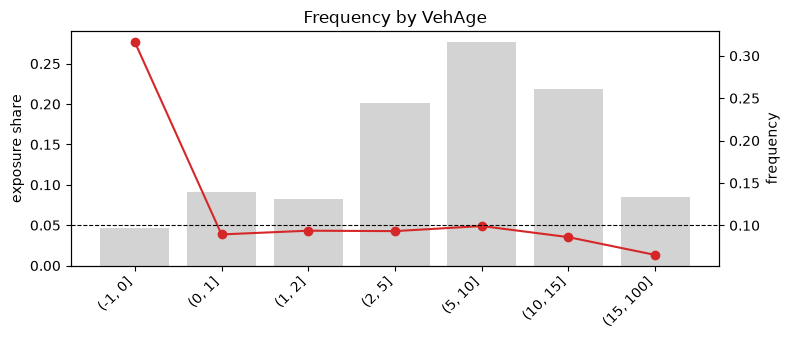

=== BonusMalus ===
            policies     exposure  claims  exposure_share    freq  relativity  \
BonusMalus                                                                      
(49, 50]      306675  179395.3337   14455          0.6283  0.0806      0.7984   
(50, 60]       75338   38169.8684    3643          0.1337  0.0954      0.9457   
(60, 70]       45407   21077.3470    2890          0.0738  0.1371      1.3586   
(70, 80]       49485   21157.3179    2688          0.0741  0.1270      1.2589   
(80, 100]      58256   22854.1133    4056          0.0800  0.1775      1.7585   
(100, 150]      6106    2804.5231    1045          0.0098  0.3726      3.6920   
(150, 350]       164      75.9182      40          0.0003  0.5269      5.2206   

                   thin  
BonusMalus               
(49, 50]                 
(50, 60]                 
(60, 70]                 
(70, 80]                 
(80, 100]                
(100, 150]               
(150, 350]  <100 claims   



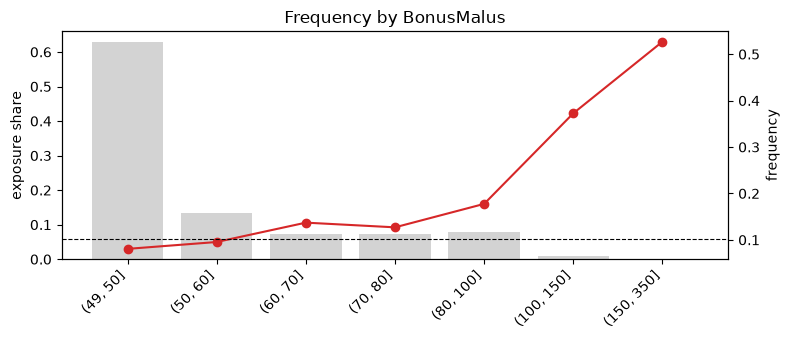

=== Density ===
               policies    exposure  claims  exposure_share    freq  \
Density                                                               
(0, 50]           84878  50705.5801    4186          0.1776  0.0826   
(50, 200]        123749  68801.9332    6188          0.2410  0.0899   
(200, 500]        88124  47617.9862    4637          0.1668  0.0974   
(500, 1500]      102683  52220.9324    5680          0.1829  0.1088   
(1500, 5000]     102454  48485.1621    5787          0.1698  0.1194   
(5000, 30000]     39543  17702.8276    2339          0.0620  0.1321   

               relativity thin  
Density                         
(0, 50]            0.8180       
(50, 200]          0.8912       
(200, 500]         0.9649       
(500, 1500]        1.0777       
(1500, 5000]       1.1826       
(5000, 30000]      1.3092        



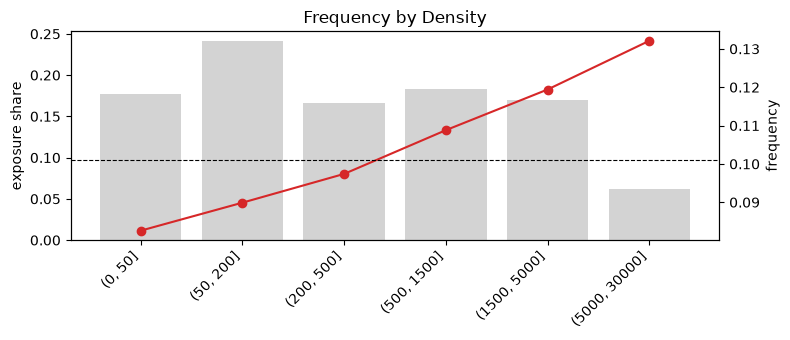

=== VehPower ===
          policies    exposure  claims  exposure_share    freq  relativity  \
VehPower                                                                     
4            92266  47972.7583    4598          0.1680  0.0958      0.9497   
5            99795  54349.2822    5846          0.1903  0.1076      1.0658   
6           118780  65665.3696    6676          0.2300  0.1017      1.0074   
7           115997  61984.4765    6033          0.2171  0.0973      0.9644   
8            37505  18087.0326    1527          0.0633  0.0844      0.8365   
9            24068  12197.8927    1387          0.0427  0.1137      1.1267   
10           25071  12291.5441    1449          0.0430  0.1179      1.1681   
11           14682   6764.7505     711          0.0237  0.1051      1.0414   
12            6471   2979.8506     279          0.0104  0.0936      0.9277   
13            2551   1280.1271     116          0.0045  0.0906      0.8979   
14            1894    949.9640      95         

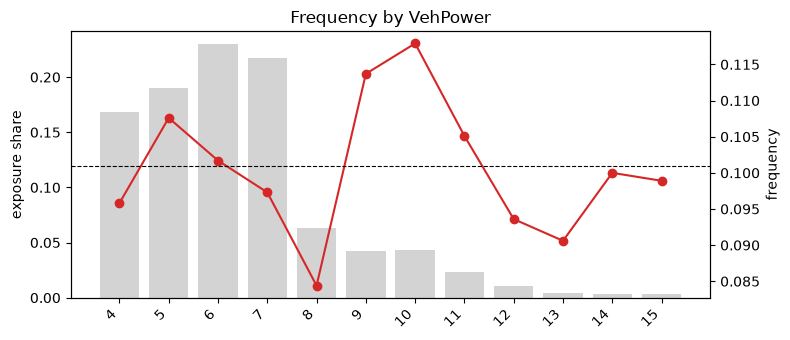

DrivAge 96-100:
         policies  exposure  claims  exposure_share    freq  relativity  \
DrivAge                                                                   
96             11      9.67       0          0.1595  0.0000       0.000   
97              9      7.60       0          0.1254  0.0000       0.000   
98              5      4.15       0          0.0685  0.0000       0.000   
99             54     37.46       4          0.6180  0.1068       1.058   
100             3      1.73       0          0.0285  0.0000       0.000   

                thin  
DrivAge               
96       <100 claims  
97       <100 claims  
98       <100 claims  
99       <100 claims  
100      <100 claims   

BonusMalus == 50 share of exposure: 0.628


In [3]:
specs = {
    "DrivAge":    [17, 21, 25, 30, 40, 50, 60, 70, 100],
    "VehAge":     [-1, 0, 1, 2, 5, 10, 15, 100],
    "BonusMalus": [49, 50, 60, 70, 80, 100, 150, 350],
    "Density":    [0, 50, 200, 500, 1500, 5000, 30000],
    "VehPower":   None,
}
for col, bins in specs.items():
    t = freq_table(train, col, bins)
    print(f"=== {col} ===")
    print(t, "\n")
    plot_freq(t, f"Frequency by {col}")

# Spot checks on the odd values seen in cleaning
print("DrivAge 96-100:")
print(freq_table(train[train["DrivAge"] >= 96], "DrivAge"), "\n")
print("BonusMalus == 50 share of exposure:",
      round(train.loc[train["BonusMalus"] == 50, "Exposure"].sum() / train["Exposure"].sum(), 3))

=== VehGas ===
         policies     exposure  claims  exposure_share    freq  relativity  \
VehGas                                                                       
Regular    276329  149686.6743   15548          0.5242  0.1039      1.0292   
Diesel     265102  135847.7473   13269          0.4758  0.0977      0.9678   

        thin  
VehGas        
Regular       
Diesel         



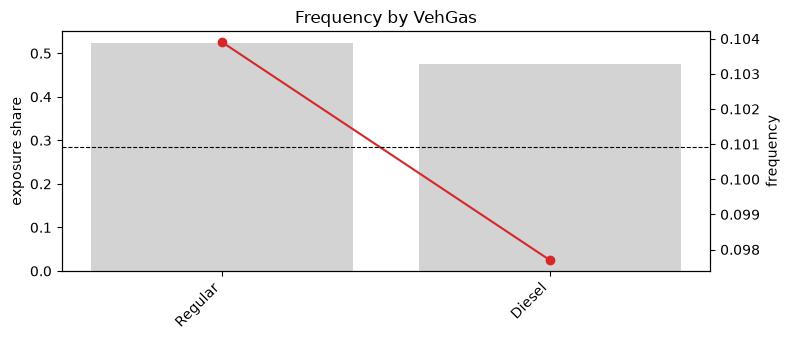

=== Area ===
      policies    exposure  claims  exposure_share    freq  relativity thin
Area                                                                       
F        14355   6456.2705     906          0.0226  0.1403      1.3905     
E       109555  50703.5432    6171          0.1776  0.1217      1.2059     
D       120847  61286.3039    6734          0.2146  0.1099      1.0887     
C       153260  83228.3519    7902          0.2915  0.0949      0.9408     
B        60429  34440.1612    3027          0.1206  0.0879      0.8709     
A        82985  49419.7909    4077          0.1731  0.0825      0.8174      



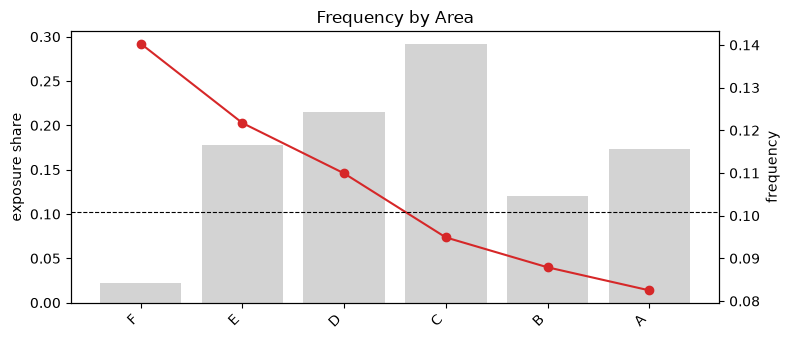

=== VehBrand ===
          policies    exposure  claims  exposure_share    freq  relativity  \
VehBrand                                                                     
B12         132625  51702.7970    7063          0.1811  0.1366      1.3536   
B11          10852   5470.1167     566          0.0192  0.1035      1.0252   
B5           27760  15891.0717    1594          0.0557  0.1003      0.9939   
B3           42525  22700.9252    2228          0.0795  0.0981      0.9725   
B13           9789   5417.2345     522          0.0190  0.0964      0.9548   
B4           20187  11043.2915    1040          0.0387  0.0942      0.9331   
B6           22736  12497.6117    1152          0.0438  0.0922      0.9133   
B1          130013  75985.3112    6990          0.2661  0.0920      0.9115   
B10          14109   7547.9861     692          0.0264  0.0917      0.9084   
B2          127563  75447.7692    6834          0.2642  0.0906      0.8975   
B14           3272   1830.3068     136         

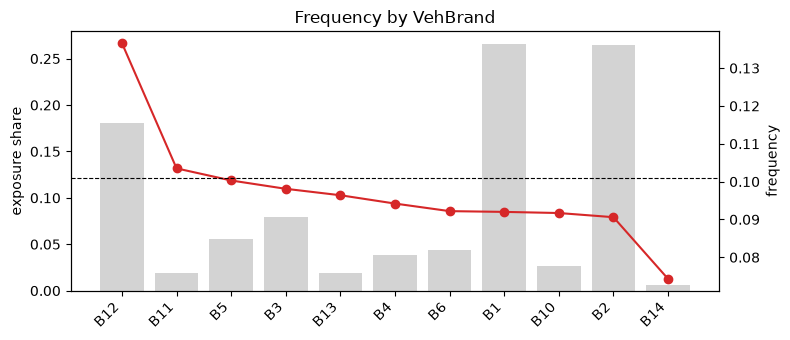

=== Region ===
                             policies    exposure  claims  exposure_share  \
Region                                                                      
Ile-de-France                   55844  24041.4766    3158          0.0842   
Champagne-Ardenne                2404    953.9241     125          0.0033   
Corse                            3583   1404.5171     179          0.0049   
Picardie                         6408   2867.8152     359          0.0100   
Rhone-Alpes                     67686  36128.0643    4013          0.1265   
Limousin                         3648   1934.5117     213          0.0068   
Alsace                           1779    979.2039     107          0.0034   
Provence-Alpes-Cotes-D'Azur     63024  28209.8978    3070          0.0988   
Languedoc-Roussillon            28357  11554.9830    1227          0.0405   
Bourgogne                        8403   3999.4529     419          0.0140   
Franche-Comte                    1051    443.6447      45    

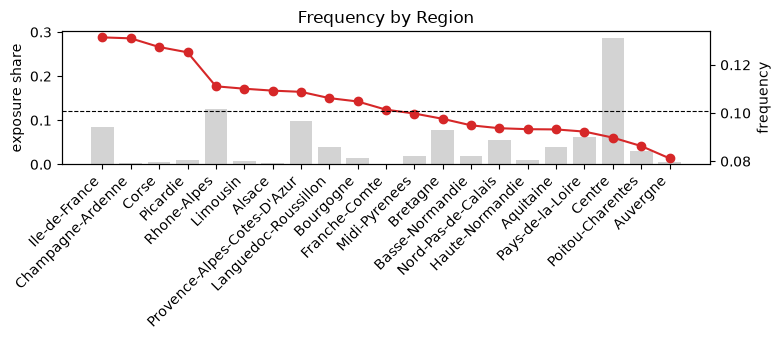

            DrivAge  VehAge  BonusMalus  VehPower  logDensity
DrivAge        1.00   -0.08       -0.57      0.04       -0.04
VehAge        -0.08    1.00        0.08     -0.00       -0.10
BonusMalus    -0.57    0.08        1.00     -0.07        0.14
VehPower       0.04   -0.00       -0.07      1.00       -0.01
logDensity    -0.04   -0.10        0.14     -0.01        1.00 

Area
A       27.0
B       71.0
C      222.0
D     1054.0
E     3744.0
F    27000.0
Name: Density, dtype: float64


In [4]:
for col in ["VehGas", "Area", "VehBrand", "Region"]:
    t = freq_table(train, col)
    print(f"=== {col} ===")
    print(t.sort_values("freq", ascending=False), "\n")
    plot_freq(t.sort_values("freq", ascending=False), f"Frequency by {col}")

# Are predictors redundant? (matters for GLM coefficients)
print(train[["DrivAge", "VehAge", "BonusMalus", "VehPower", "logDensity"]]
      .corr(method="spearman").round(2), "\n")
print(train.groupby("Area")["Density"].median().round(0))